# Notebook 01b: Realce de imágenes, uso de Funciones y visualización en RGB


# 1. Realce o estirado de imágenes a partir del histograma

## 1.1 Mejorar la visualización de una imagen

Ya aprendimos cómo leer una imagen como array de NumPy y cómo visualizar su histograma. Ahora aprovecharemos esos recursos para aplicar realces o estirados de imágenes para mejorar el contraste visual. Vamos a trabajar con una imagen satelital SPOT de un solo canal y jugar con sus niveles de grises. Por ahora la trataremos como una imagen más; en la Clase 02 veremos las particularidades que tiene como imagen geoespacial.

```python
import gdown
import matplotlib.image as mpimg

# ID del archivo de Google Drive
file_id = "1kB4Mm_kHsq4mJoO-fL-ubaLmkWt31OfJ"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "spot_pancromatica.tif"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
imagen_spot = mpimg.imread(output)

```


In [1]:
import gdown
import matplotlib.image as mpimg

# ID del archivo de Google Drive
file_id = "1kB4Mm_kHsq4mJoO-fL-ubaLmkWt31OfJ"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "spot_pancromatica.tif"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
imagen_spot = mpimg.imread(output)

Downloading...
From: https://drive.google.com/uc?id=1kB4Mm_kHsq4mJoO-fL-ubaLmkWt31OfJ
To: /content/spot_pancromatica.tif
100%|██████████| 57.0M/57.0M [00:00<00:00, 138MB/s]


Veamos algunas características de esta imagen antes de visualizarla:

```python
import numpy as np

print('\nTipo de objeto:', type(imagen_spot))
print('\nDimensiones:', imagen_spot.shape)
print('\nTipo de dato:', imagen_spot.dtype)
print('\nRango de datos:', f'{np.min(imagen_spot)} - {np.max(imagen_spot)}')
print('\nMatriz de datos: \n', imagen_spot)
```

In [2]:
import numpy as np

print('\nTipo de objeto:', type(imagen_spot))
print('\nDimensiones:', imagen_spot.shape)
print('\nTipo de dato:', imagen_spot.dtype)
print('\nRango de datos:', f'{np.min(imagen_spot)} - {np.max(imagen_spot)}')
print('\nMatriz de datos: \n', imagen_spot)


Tipo de objeto: <class 'numpy.ndarray'>

Dimensiones: (3956, 7204)

Tipo de dato: uint16

Rango de datos: 1 - 4095

Matriz de datos: 
 [[784 711 689 ... 409 409 408]
 [865 771 678 ... 398 392 383]
 [737 655 594 ... 399 388 370]
 ...
 [537 536 516 ... 707 670 613]
 [556 545 503 ... 627 583 518]
 [543 517 461 ... 564 520 454]]


Podemos ver que se trata de una matriz con 3956 filas y 7204 columnas, de tipo `uint16`, que quiere decir que almacena números enteros no negativos de 16 bits (es decir, de 0 a $2^{16}$, o 0 a 65536). Los tipos de datos aceptados por los arrays de NumPy son variados y se pueden consultar en este [enlace](https://numpy.org/doc/stable/user/basics.types.html). Su valor mínimo es 1 y su máximo es 4095, lo cual nos puede ayudar a decidir cuántos `bins` usar para su histograma.

A continuación visualizamos la imagen junto a su histograma, al cual le pasaremos el valor `4095` en el parámetro `bins`.

```python
from matplotlib import pyplot as plt

# Redimensionar el array para el histograma
image_flat = imagen_spot.ravel()  # Reordenar la imagen a un vector 1D

# Crear la figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_spot, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Imagen SPOT")

# Mostrar el histograma
axes[1].hist(image_flat,bins = 4095, color="blue", alpha=0.7)
axes[1].set_title("Histograma de intensidades")
axes[1].set_xlabel("Valor de intensidad")
axes[1].set_ylabel("Frecuencia")

# Mostrar el gráfico
plt.show()
```


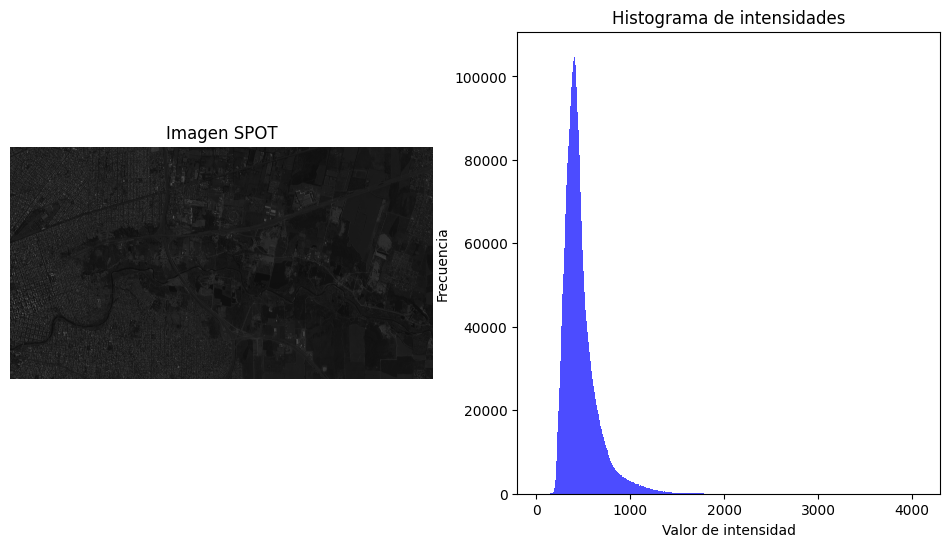

In [3]:
from matplotlib import pyplot as plt

# Redimensionar el array para el histograma
image_flat = imagen_spot.ravel()  # Reordenar la imagen a un vector 1D

# Crear la figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_spot, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Imagen SPOT")

# Mostrar el histograma
axes[1].hist(image_flat,bins = 4095, color="blue", alpha=0.7)
axes[1].set_title("Histograma de intensidades")
axes[1].set_xlabel("Valor de intensidad")
axes[1].set_ylabel("Frecuencia")

# Mostrar el gráfico
plt.show()

Se advierte en el histograma que la mayoría de los valores se concentra en un rango numérico aproximado de 200 a 1800, lo cual explica el bajo contraste que muestra la imagen. Vamos a aplicar un _slicing_ que aprendimos en la Notebook anterior sobre la imagen para extraer una zona más pequeña. También computaremos algunas estadísticas, como el mínimo, el máximo, la media, y los percetiles 1 y 99.

```python
# Extraer una sub-imagen de 1500 por 1500
imagen_subset = imagen_spot[1000:2500, 1000:2500]

# Calcular estadísticas
vmin = np.nanmin(imagen_subset)
vmax = np.nanmax(imagen_subset)
vmean = np.nanmean(imagen_subset)
vstd = np.nanstd(imagen_subset)
p1, p99 = np.percentile(imagen_subset, (1, 99))

# Imprimir los valores
print('Valor mínimo:', vmin, '\n')
print('Valor máximo:', vmax, '\n')
print('Valor medio:', vmean, '\n')
print('Valor del desvío estándar:', vstd, '\n')
print('Valor del percentil 1:', p1, '\n')
print('Valor del percentil 99:', p99, '\n')
```



In [4]:
# Extraer una sub-imagen de 1500 por 1500
imagen_subset = imagen_spot[1000:2500, 1000:2500]

# Calcular estadísticas
vmin = np.nanmin(imagen_subset)
vmax = np.nanmax(imagen_subset)
vmean = np.nanmean(imagen_subset)
vstd = np.nanstd(imagen_subset)
p1, p99 = np.percentile(imagen_subset, (1, 99))

# Imprimir los valores
print('Valor mínimo:', vmin, '\n')
print('Valor máximo:', vmax, '\n')
print('Valor medio:', vmean, '\n')
print('Valor del desvío estándar:', vstd, '\n')
print('Valor del percentil 1:', p1, '\n')
print('Valor del percentil 99:', p99, '\n')

Valor mínimo: 82 

Valor máximo: 4093 

Valor medio: 480.3786137777778 

Valor del desvío estándar: 182.3153291404957 

Valor del percentil 1: 225.0 

Valor del percentil 99: 1141.0 



Visualicemos el histograma de este recorte con los respectivos valores estadísticos calculados:

```python
from matplotlib import pyplot as plt

# Redimensionar el array para el histograma
imagen_subset_flat = imagen_subset.ravel()  # Aplanar la imagen a un vector 1D

# Crear la figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_subset, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Imagen SPOT - Recorte")

# Mostrar el histograma
axes[1].hist(imagen_subset_flat,bins = 50, color="green", alpha=0.7)
axes[1].set_title("Histograma de intensidades")
axes[1].set_xlabel("Valor de intensidad")
axes[1].set_ylabel("Frecuencia")
axes[1].axvline(vmin, color='blue', linestyle='dashed', linewidth=2, label=f'Mín: {vmin:.2f}')
axes[1].axvline(vmax, color='red', linestyle='dashed', linewidth=2, label=f'Máx: {vmax:.2f}')
axes[1].axvline(vmean, color='purple', linestyle='dashed', linewidth=2, label=f'Media: {vmean:.2f}')
axes[1].axvline(p1, color='black', linestyle='dashed', linewidth=2, label=f'Perc. 1%: {p1:.2f}')
axes[1].axvline(p99, color='pink', linestyle='dashed', linewidth=2, label=f'Perc. 99%: {p99:.2f}')
axes[1].legend()

# Mostrar el gráfico
plt.show()
```

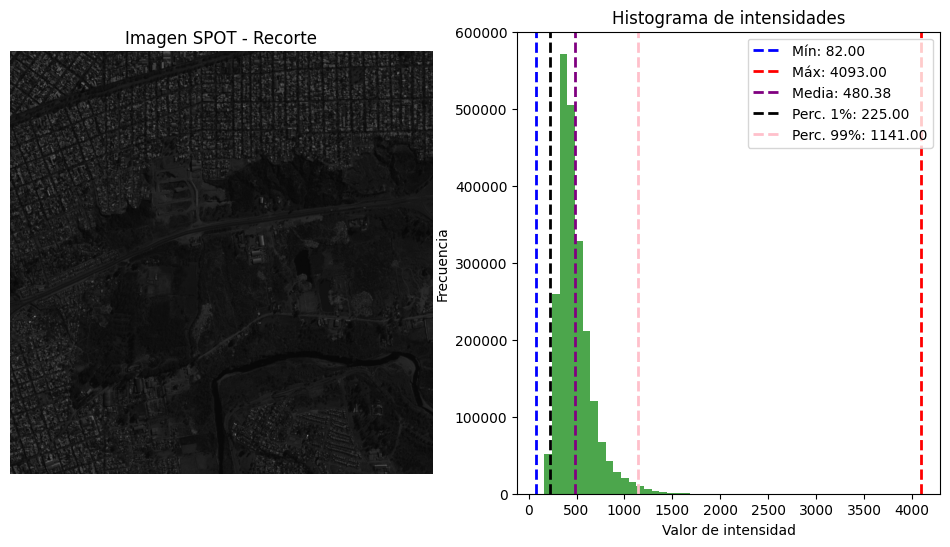

In [5]:
from matplotlib import pyplot as plt

# Redimensionar el array para el histograma
imagen_subset_flat = imagen_subset.ravel()  # Aplanar la imagen a un vector 1D

# Crear la figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_subset, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Imagen SPOT - Recorte")

# Mostrar el histograma
axes[1].hist(imagen_subset_flat,bins = 50, color="green", alpha=0.7)
axes[1].set_title("Histograma de intensidades")
axes[1].set_xlabel("Valor de intensidad")
axes[1].set_ylabel("Frecuencia")
axes[1].axvline(vmin, color='blue', linestyle='dashed', linewidth=2, label=f'Mín: {vmin:.2f}')
axes[1].axvline(vmax, color='red', linestyle='dashed', linewidth=2, label=f'Máx: {vmax:.2f}')
axes[1].axvline(vmean, color='purple', linestyle='dashed', linewidth=2, label=f'Media: {vmean:.2f}')
axes[1].axvline(p1, color='black', linestyle='dashed', linewidth=2, label=f'Perc. 1%: {p1:.2f}')
axes[1].axvline(p99, color='pink', linestyle='dashed', linewidth=2, label=f'Perc. 99%: {p99:.2f}')
axes[1].legend()

# Mostrar el gráfico
plt.show()

Para mejorar la visualización de la imagen se pueden usar los parámetros _vmin_ y _vmax_ de _imshow()_. Cuando no se pasa ningún valor, estos parámetros toman por defecto el mínimo y el máximo de la imagen, pero cuando se pasan valores distintos, _imshow()_ hace el escalado de la imagen mejorando su contraste. Mientras más pequeño el rango numérico, mayor el contraste.

```python
# Crear la figura con tres subgráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_subset, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Original")

# Mostrar la imagen estirada a los percentiles 1-99
axes[1].imshow(imagen_subset, cmap="gray", vmin = p1, vmax = p99)  # Mostrar en escala de grises
axes[1].axis("off")  # Ocultar los ejes
axes[1].set_title("Estirado al 1%-99%")

# Mostrar la imagen estirada a la media +/- 1 desvío estándar
axes[2].imshow(imagen_subset, cmap="gray", vmin = vmean - vstd, vmax = vmean + vstd)  # Mostrar en escala de grises
axes[2].axis("off")  # Ocultar los ejes
axes[2].set_title("Estirado a media +/- 1 destvío estándar")

plt.show()
```

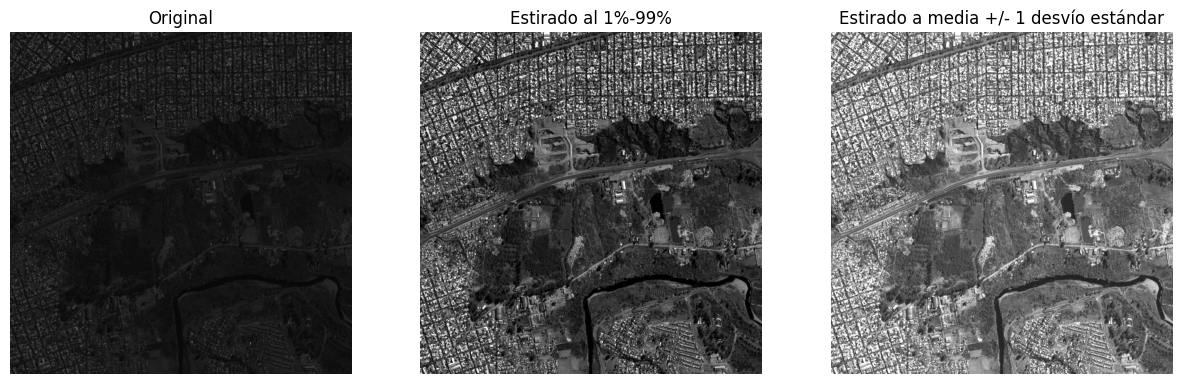

In [9]:
# Crear la figura con tres subgráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Mostrar la imagen original
axes[0].imshow(imagen_subset, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Original")

# Mostrar la imagen estirada a los percentiles 1-99
axes[1].imshow(imagen_subset, cmap="gray", vmin = p1, vmax = p99)  # Mostrar en escala de grises
axes[1].axis("off")  # Ocultar los ejes
axes[1].set_title("Estirado al 1%-99%")

# Mostrar la imagen estirada a la media +/- 1 desvío estándar
axes[2].imshow(imagen_subset, cmap="gray", vmin = vmean - 2*vstd, vmax = vmean + 2*vstd)  # Mostrar en escala de grises
axes[2].axis("off")  # Ocultar los ejes
axes[2].set_title("Estirado a media +/- 1 desvío estándar")

plt.show()

## 1.2. Re-escalado de la imagen

Las opciones _vmin_ y _vmax_ son útiles para mejorar la visualización de la imagen _al vuelo_. Sin embargo, para visualizar imágenes en RGB (siguiente sección) es necesario re-escalar cada uno de los canales o bandas de color, ya que imshow() no permite usar un valor mínimo y máximo diferente para cada uno. Por lo tanto, en esta sección veremos cómo hacer ese escalado.

Repasemos el proceso de reescalado de la imagen, suponiendo que queremos usar los percentiles 1 y 99

### 1.2.1. Recorte de valores extremos

Dado un conjunto de valores de píxeles \( I \) en la imagen original, se calculan los percentiles 1 y 99:

$$
valor_{min} = P_1(I), valor_{max} = P_{99}(I)
$$

donde:
- \$P_1(I) $ es el valor del percentil 1 (el 1% de los valores están por debajo de este).  

- \$P_{99}(I) $ es el valor del percentil 99 (el 99% de los valores están por debajo de este).

Luego, se aplica un recorte para limitar los valores de la imagen dentro de este rango:

$$
I_{\text{truncada}}(x, y) = \max(valor_{min}, \min(I(x, y), valor_{max}))
$$

Esto significa que:
- Todos los valores menores a $valor_{min}$ se igualan a $valor_{min}$.
- Todos los valores mayores a $valor_{max}$ se igualan a $valor_{max}$.
- Los valores entre $valor_{min}$ y $valor_{max}$ permanecen sin cambios.

Código:

```python
# Calcular los percentiles 1 y 99
valor_min = np.percentile(imagen_subset, 1)
valor_max = np.percentile(imagen_subset, 99)

# Estirar la imagen al rango [p1, p99]
ecualizada = np.clip(imagen_subset, valor_min, valor_max)  # Limitar los valores a este rango
```

`np.clip()` nos sirve para _truncar_ la imagen al rango $valor_{min},valor_{max}$

In [10]:
# Calcular los percentiles 1 y 99
valor_min = np.percentile(imagen_subset, 1)
valor_max = np.percentile(imagen_subset, 99)

# Estirar la imagen al rango [p1, p99]
ecualizada = np.clip(imagen_subset, valor_min, valor_max)  # Limitar los valores a este rango

### 1.2.2. Normalización lineal al rango [0, 255]

Una vez que la imagen ha sido recortada o truncada, se la normaliza al intervalo \([0, 255]\) utilizando la siguiente fórmula:

$$
I_{\text{normalizada}}(x, y) = \frac{I_{\text{truncada}}(x, y) - valor_{min}}{valor_{max} - valor_{min}} \times 255
$$

### **Explicación matemática**
1. El numerador $I_{\text{clipped}}(x, y) - valor_{min}$  desplaza el rango de valores para que $valor_{min}$ se convierta en 0.  


2. La división $\frac{I_{\text{truncada}}(x, y) - valor_{min}}{valor_{max} - valor_{min}}$ Normaliza los valores al rango \([0, 1]\).  


3. La multiplicación $\times 255$ escala los valores al rango [0, 255], que corresponde a datos en 8 bits.

También podríamos omitirlo, lo cual dejaría la imagen escalada al rango [0,1].

Código:

```python
# Normalizar a 0-255
ecualizada = (ecualizada - valor_min) / (valor_max - valor_min) * 255 # Si sacamos este *255 queda escalada de 0 a 1

# Convertir la imagen ecualizada a entero de 8 bits (ya que la normalizamos y escalamos de 0 a 255)
ecualizada = np.uint8(ecualizada)
```

In [11]:
# Normalizar a 0-255
ecualizada = (ecualizada - valor_min) / (valor_max - valor_min) * 255 # Si sacamos este *255 queda escalada de 0 a 1

# Convertir la imagen ecualizada a entero de 8 bits (ya que la normalizamos y escalamos de 0 a 255)
ecualizada = np.uint8(ecualizada)

### 1.2.3. Efecto en el histograma

  
- Los valores por debajo de $valor_{min}$ y por encima de $valor_{max}$ se agrupan entre 0 y 255 respectivamente, generando **picos** en los extremos del histograma.
  
- Los valores que originalmente estaban en el intervalo $valor_{min}, valor_{max}$ ahora _se estiran_ a todo el rango [0, 255], aumentando el contraste de la imagen.

- Debido a la transformación lineal, algunos valores pueden agruparse más que otros, creando un efecto de "dentado" en el histograma. Esto es muy sensible a la cantidad de _bins_ que usemos para representar el histograma.

El siguiente código ayuda a ver el cambio:

```python
# Crear una figura con 2 filas: imágenes e histogramas originales y escalados
fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})

# ---------------------- IMÁGENES ----------------------
axes[0, 0].imshow(imagen_subset, cmap='gray')
axes[0, 0].set_title('Imagen Original')
axes[0, 0].axis('off')

axes[0, 1].imshow(ecualizada, cmap='gray')
axes[0, 1].set_title('Imagen Ecualizada')
axes[0, 1].axis('off')

# ---------------------- HISTOGRAMAS ----------------------
# Histograma de la imagen original
axes[1, 0].hist(imagen_subset.ravel(), bins=256, color='gray', alpha=0.7)
axes[1, 0].set_title('Histograma Original')

# Histograma de la imagen ecualizada
axes[1, 1].hist(ecualizada.ravel(), bins=256, color='gray', alpha=0.7)
axes[1, 1].set_title('Histograma Ecualizado')

# Ajustar el diseño
plt.tight_layout()
plt.show()
```

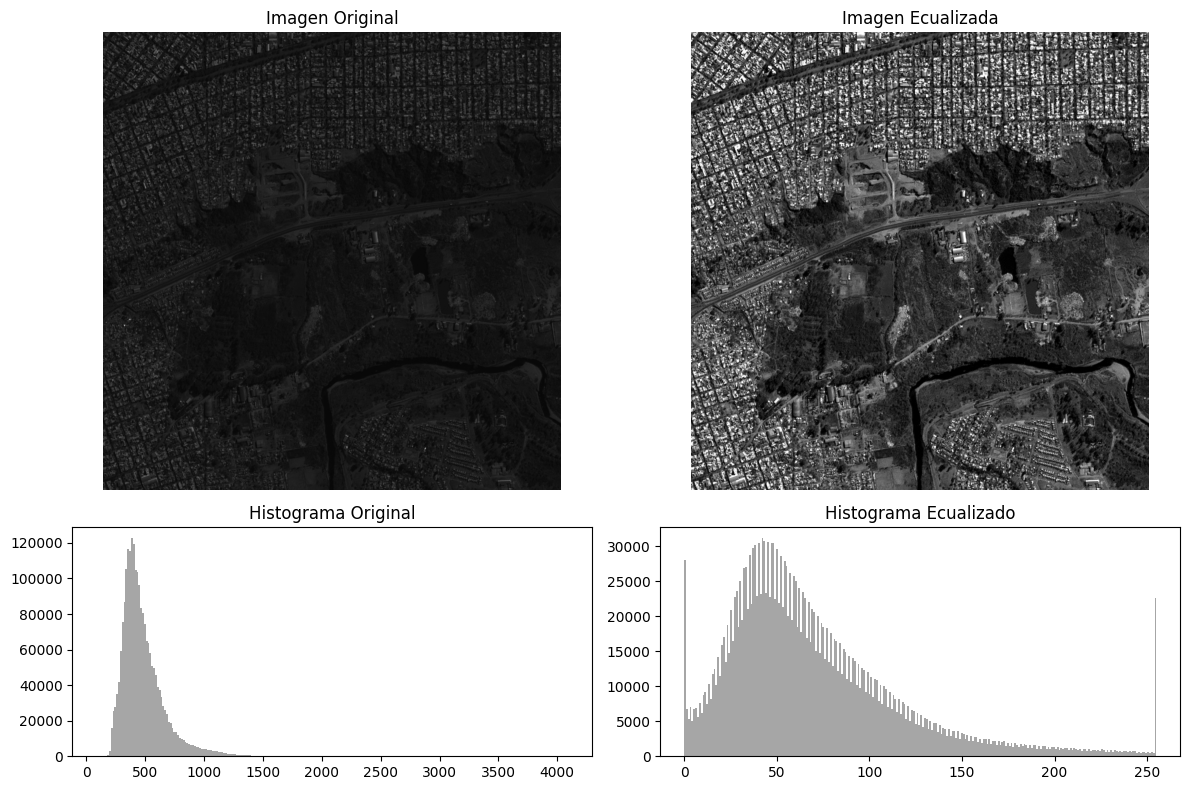

In [12]:
# Crear una figura con 2 filas: imágenes e histogramas originales y escalados
fig, axes = plt.subplots(2, 2, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})

# ---------------------- IMÁGENES ----------------------
axes[0, 0].imshow(imagen_subset, cmap='gray')
axes[0, 0].set_title('Imagen Original')
axes[0, 0].axis('off')

axes[0, 1].imshow(ecualizada, cmap='gray')
axes[0, 1].set_title('Imagen Ecualizada')
axes[0, 1].axis('off')

# ---------------------- HISTOGRAMAS ----------------------
# Histograma de la imagen original
axes[1, 0].hist(imagen_subset.ravel(), bins=256, color='gray', alpha=0.7)
axes[1, 0].set_title('Histograma Original')

# Histograma de la imagen ecualizada
axes[1, 1].hist(ecualizada.ravel(), bins=256, color='gray', alpha=0.7)
axes[1, 1].set_title('Histograma Ecualizado')

# Ajustar el diseño
plt.tight_layout()
plt.show()

## 1.3.Uso de funciones

El escalado de las imágenes es una de las operaciones más habituales que tenemos que hacer cuando queremos visualizar. Realizarlo para una sola imagen es relativamente fácil, pero si trabajamos con más imágenes puede resultar engorroso hacer una y otra vez las mismas operaciones (calcular percentiles, truncar la imagen, escalarla), lo cual podemos simplicar desarrollando una **función**.

### 1.3.1. Repaso: ¿Qué son las funciones?

Como vimos en el Bloque 02, las funciones en un lenguaje de programación, son partes de código que encapsulan un conjunto de instrucciones, facilitando su uso y permitiendo su reutilización, tanto a lo largo del nuestro programa, como por programas externos. Las funciones se componen de las siguientes partes:

![funcion.png](https://drive.google.com/uc?id=11Q3tM_xHM8oDnWG_4-yPT9yyW2_ZgE3z)

### 1.3.2. Función de re-escalado

Si tenemos que pensar en una función que haga el escalado de una imagen, tendríamos que pensar sus parámetros de entrada, el proceso que hace dentro del bloque principal, y su salida.

- _Parámetros de entrada_: Por un lado, la imagen a escalar. Por otro lado, los valores mínimo y máximo para ese escalado. Pero sería ideal que, si son percentiles, la función se encargue de calcularlos. Entonces, podemos pasarle un valor `p`que vaya de 0 a 100, de manera tal que el cálculo de los percentiles se haga haciendo `vmin,vmax = np.percentile(imagen, (p,100-p))`. Es decir, si por ejemplo pasamos el valor `p = 2`, la función calculará los percentiles 2 y 98.

- _Bloque principal_: Aquí se realizaría el cálculo de los percentiles, el recorte de los valores extremos (paso 1.2.1) y la normalización lineal al rango `[0,255]` (paso 1.2.2).

- _Salida_: La salida sería la imagen `ecualizada`.

Veamos la forma de esta función:

```python
def escalar_imagen(imagen, p):
  # Calcular los percentiles p y 100-p
  valor_min = np.percentile(imagen, p)
  valor_max = np.percentile(imagen, 100-p)

  # Truncar la imagen al rango [p1, p99]
  ecualizada = np.clip(imagen, valor_min, valor_max)

  # Normalizar la imagen al rango 0-255.
  ecualizada = (ecualizada - valor_min) / (valor_max - valor_min) * 255

  # Convertir la imagen ecualizada a entero de 8 bits
  ecualizada = np.uint8(ecualizada)

  # Retornar la imagen ecualizada
  return ecualizada
```

In [13]:
def escalar_imagen(imagen, p):
  # Calcular los percentiles p y 100-p
  valor_min = np.percentile(imagen, p)
  valor_max = np.percentile(imagen, 100-p)

  # Truncar la imagen al rango [p1, p99]
  ecualizada = np.clip(imagen, valor_min, valor_max)

  # Normalizar la imagen al rango 0-255.
  ecualizada = (ecualizada - valor_min) / (valor_max - valor_min) * 255

  # Convertir la imagen ecualizada a entero de 8 bits
  ecualizada = np.uint8(ecualizada)

  # Retornar la imagen ecualizada
  return ecualizada

Probemos ahora nuestra función, generando imágenes ecualizadas con distintos valores de percentl:

```python
# Aplicar la función escalar_imagen con tres rangos distintos:
ecualizada_1_99 = escalar_imagen(imagen_subset, 1)
ecualizada_10_90 = escalar_imagen(imagen_subset, 10)
ecualizada_20_80 = escalar_imagen(imagen_subset, 20)

# Crear la figura con tres subgráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Mostrar la imagen estirada a los percentiles 1-99
axes[0].imshow(ecualizada_1_99, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Estirado al 1%-99%")

# Mostrar la imagen estirada a los percentiles 10-90
axes[1].imshow(ecualizada_10_90, cmap="gray")  # Mostrar en escala de grises
axes[1].axis("off")  # Ocultar los ejes
axes[1].set_title("Estirado al 10%-90%")

# Mostrar la imagen estirada a los percentiles 20-80
axes[2].imshow(ecualizada_20_80, cmap="gray")  # Mostrar en escala de grises
axes[2].axis("off")  # Ocultar los ejes
axes[2].set_title("Estirado al 20%-80%")

plt.show()
```

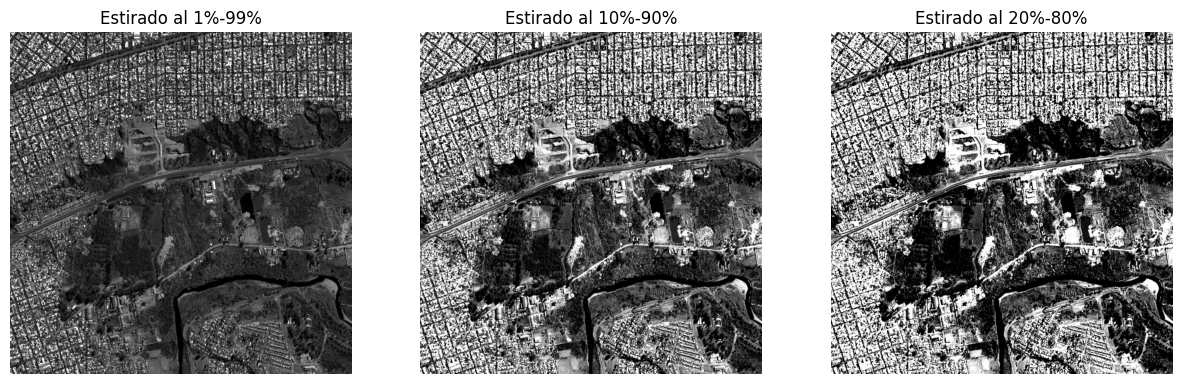

In [22]:
# Aplicar la función escalar_imagen con tres rangos distintos:
ecualizada_1_99 = escalar_imagen(imagen = imagen_subset, p=1)
ecualizada_10_90 = escalar_imagen(imagen_subset, 10)
ecualizada_20_80 = escalar_imagen(imagen_subset, 20)

# Crear la figura con tres subgráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Mostrar la imagen estirada a los percentiles 1-99
axes[0].imshow(ecualizada_1_99, cmap="gray")  # Mostrar en escala de grises
axes[0].axis("off")  # Ocultar los ejes
axes[0].set_title("Estirado al 1%-99%")

# Mostrar la imagen estirada a los percentiles 10-90
axes[1].imshow(ecualizada_10_90, cmap="gray")  # Mostrar en escala de grises
axes[1].axis("off")  # Ocultar los ejes
axes[1].set_title("Estirado al 10%-90%")

# Mostrar la imagen estirada a los percentiles 20-80
axes[2].imshow(ecualizada_20_80, cmap="gray")  # Mostrar en escala de grises
axes[2].axis("off")  # Ocultar los ejes
axes[2].set_title("Estirado al 20%-80%")

plt.show()

### Ejercicio

Aplicar la función `escalar_imagen` sobre la imagen de Homero usada en la Notebook anterior. Plotear los distintos resultados

```python
# ID del archivo de Google Drive
file_id = "1UcOa7FCF03RnNyiXo5JOHxNmOrjWPIqM"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "homero2.jpg"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
image = mpimg.imread(output)
```

# 2. Visualización de imágenes en color RGB

Ahora tenemos las herramientas para visualizar imágenes de más de un canal (o _bandas_ como empezaremos a referirnos en el caso satelital). Utilizaremos otra imagen satelital SPOT que tiene 4 canales distintos, y usaremos las función desarrollada para generar composiciones en RGB.

El archivo se llama **SPOT_20170806_MS_p.tif**. En él vamos a encontrar las siguientes bandas o canales:

- Banda 1: Azul (B)
- Banda 2: Verde (G)
- Banda 3: Rojo (R)
- Banda 4: Infrarrojo cercano (NIR)

El archivo que visualizaremos aquí corresponde aproximadamente a la zona remarcada en la imagen:

<p align="left">
 <img src="https://drive.google.com/uc?id=1QIAxyqvAct5lIfnRJq2ZQE5VNh4OvMYZ" width="500" >
</p>



## 2.1. Abrir las imágenes y ver su histograma

Las librerías `matplotlib` y `PIL` no pueden leer archivos `.tif` de múltiples canales, por lo que usaremos para leer la imagen como array la librería `Scikit-image`:

```python
# ID del archivo de Google Drive
file_id = "12nir9oKR-9qra749qtndlz_vAYrqgIen"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "spot_apilada.tif"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
from skimage import io
imagen_spot_apilada = io.imread("spot_apilada.tif")

# Ver las dimensiones de la imagen cargada
print(f"Dimensiones de la imagen SPOT: {imagen_spot_apilada.shape}")

# Ver el tipo de dato
print(f"Tipo de dato: {imagen_spot_apilada.dtype}")
```

In [23]:
# ID del archivo de Google Drive
file_id = "12nir9oKR-9qra749qtndlz_vAYrqgIen"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "spot_apilada.tif"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
from skimage import io
imagen_spot_apilada = io.imread("spot_apilada.tif")

# Ver las dimensiones de la imagen cargada
print(f"Dimensiones de la imagen SPOT: {imagen_spot_apilada.shape}")

# Ver el tipo de dato
print(f"Tipo de dato: {imagen_spot_apilada.dtype}")

Downloading...
From: https://drive.google.com/uc?id=12nir9oKR-9qra749qtndlz_vAYrqgIen
To: /content/spot_apilada.tif
100%|██████████| 7.20M/7.20M [00:00<00:00, 26.9MB/s]


Dimensiones de la imagen SPOT: (600, 750, 4)
Tipo de dato: float32


La imagen leída como array tiene las siguientes dimensiones: `(650, 750 ,4)`, que corresponden a filas, columnas y canales o bandas respectivamente. Podemos visualizarla usando _imshow_ de _Matplotlib_ y también podemos graficar su histograma. Visualizar el histograma con barras en un mismo gráfico puede ser difícil de interpretar porque ahora tenemos 4 canales diferentes, es decir 4 imágenes en un mismo archivo. Nos podemos ayudar para eso con la función `kdeplot()` de la librería `Seaborn`, que aproxima la densidad de probabilidad en cada punto, generando una curva continua y suavizada.

```python
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  # Para curvas de densidad más suaves

# Crear la figura con 1 fila y 2 columnas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen (suponiendo que tiene múltiples bandas)
ax[0].imshow(imagen_spot_apilada)
ax[0].set_title("Imagen Multicanal")
ax[0].axis("off")

# Colores para cada banda en el histograma
colores = ["red", "green", "blue", "yellow"]  

# Dibujar curvas de densidad para cada banda
for i in range(imagen_spot_apilada.shape[-1]):  # Hasta 4 bandas
    sns.kdeplot(imagen_spot_apilada[:,:,i].ravel(), color=colores[i], label=f"Banda {i+1}", ax=ax[1], linewidth=2)

ax[1].set_title("Densidad de Intensidades por Banda")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Densidad")
ax[1].legend()

plt.tight_layout()
plt.show()
```

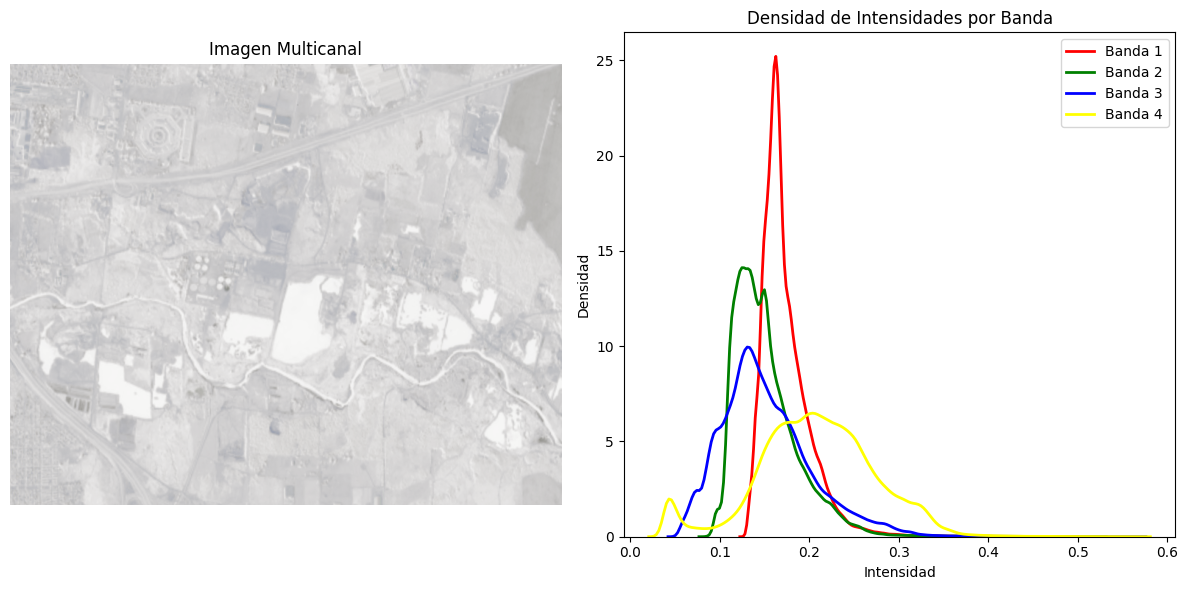

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  # Para curvas de densidad más suaves

# Crear la figura con 1 fila y 2 columnas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen (suponiendo que tiene múltiples bandas)
ax[0].imshow(imagen_spot_apilada)
ax[0].set_title("Imagen Multicanal")
ax[0].axis("off")

# Colores para cada banda en el histograma
colores = ["red", "green", "blue", "yellow"]

# Dibujar curvas de densidad para cada banda
for i in range(imagen_spot_apilada.shape[-1]):  # Hasta 4 bandas
    sns.kdeplot(imagen_spot_apilada[:,:,i].ravel(), color=colores[i], label=f"Banda {i+1}", ax=ax[1], linewidth=2)

ax[1].set_title("Densidad de Intensidades por Banda")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Densidad")
ax[1].legend()

plt.tight_layout()
plt.show()

El histograma suavizado muestra que los píxeles de cada banda o canal tienen valores decimales (flotanes), y están casi todos concentrados en el rango 0 a 0.5. En la clase 02 veremos cómo estos valores varían en función de la superficie que estamos viendo en la imagen satelital.

### Para pensar...

En el ploteo anterior, la imagen se ve como si estuviera "saturada". ¿A qué se puede deber esto? ¿Cómo lo podríamos arreglar? Para debatir en clase ...

## 2.2. Mejorar la visualización de la imagen en RGB

El ploteo de _imshow()_ en la celda anterior parece mostrar una imagen en escala de grises. Sin embargo, esto se debe a que una composición de color RGB hecha con _Matplotlib_ necesita que los tres canales o imágenes que se ponen estén normalizadas como se hizo en la sección anterior con la imagen pancromática. También, por defecto, _imshow()_ está poniendo la primer imagen o banda en el canal _rojo_, la segunda en el _verde_ y la tercera en el _azul_. Más adelante veremos que podemos manipular ese orden.

Para mejorar la visualización, podemos aplicar `escalar_imagen()` a cada una de las imágenes o bandas de la escena SPOT. Veamos cómo se hace por ejemplo para la primer banda:

```python
imagen1_escalada = escalar_imagen(imagen_spot_apilada[:, :, 0], 1)
```

La línea anterior genera una imagen ecualizada o estiada a los percentiles 1-99, tomando la primer imagen de la pila de imágenes. Prestar atención a como se usa la indezación sobre el array: `imagen_spot_apilada[:, :, 0]` quiere decir, **todas las filas (:), todas las columnas (:) y el primer elemento de la dimensión 3, es decir la primer imagen o banda**.

In [33]:
imagen1_escalada = escalar_imagen(imagen_spot_apilada[:, :, 0], 1)

Vamos a hacer lo mismo con las otras bandas o imágenes:

```python
imagen2_escalada = escalar_imagen(imagen_spot_apilada[:, :, 1], 1)
imagen3_escalada = escalar_imagen(imagen_spot_apilada[:, :, 2], 1)
imagen4_escalada = escalar_imagen(imagen_spot_apilada[:, :, 3], 1)
```

In [34]:
imagen2_escalada = escalar_imagen(imagen_spot_apilada[:, :, 1], 1)
imagen3_escalada = escalar_imagen(imagen_spot_apilada[:, :, 2], 1)
imagen4_escalada = escalar_imagen(imagen_spot_apilada[:, :, 3], 1)

Para generar la visualización en RGB, es necesario volver a _apilarlas_ porque quedaron como arrays separados. Para esto hay distintas opciones. Una por ejemplo es usar `np.array()` para reconstruir un array de 4 bandas, y luego usar `np.transpose()` para reordenar los ejes, ya que _imshow_ necesita que el array RGB tenga estructura `(fila,columa,banda)`:

```python
imagen_escalada = np.array((imagen1_escalada, imagen2_escalada, imagen3_escalada, imagen4_escalada))
imagen_escalada = np.transpose(imagen_escalada, axes = (1,2,0))

# Verificar que las dimensiones sean (fila,columna,banda):
print(f"Dimensiones de la imagen re-escalada: {imagen_escalada.shape}")
```

In [37]:
imagen_escalada = np.array((imagen1_escalada, imagen2_escalada, imagen3_escalada, imagen4_escalada))

imagen_escalada = np.transpose(imagen_escalada, axes = (1,2,0))

# Verificar que las dimensiones sean (fila,columna,banda):
print(f"Dimensiones de la imagen re-escalada: {imagen_escalada.shape}")

Dimensiones de la imagen re-escalada: (600, 750, 4)


Ahora sí, podemos repetir la visualización de la imagen y la veremos con más contraste entre los colores. También notaremos cambio en el histograma, dado que se _estiró_ al rango 0-255:

```python
# Crear la figura con 1 fila y 2 columnas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen (suponiendo que tiene múltiples bandas)
ax[0].imshow(imagen_escalada[:,:,:3]) # Estamos mostrando solo las primeras 3 bandas
ax[0].set_title("Imagen Multicanal Reescalada")
ax[0].axis("off")

# Colores para cada banda en el histograma
colores = ["red", "green", "blue", "yellow"]  

# Dibujar curvas de densidad para cada banda
for i in range(imagen_escalada.shape[-1]):  # Hasta 4 bandas
    sns.kdeplot(imagen_escalada[:,:,i].ravel(), color=colores[i], label=f"Banda {i+1}", ax=ax[1], linewidth=2)

ax[1].set_title("Densidad de Intensidades por Banda")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Densidad")
ax[1].legend()

plt.tight_layout()
plt.show()
```



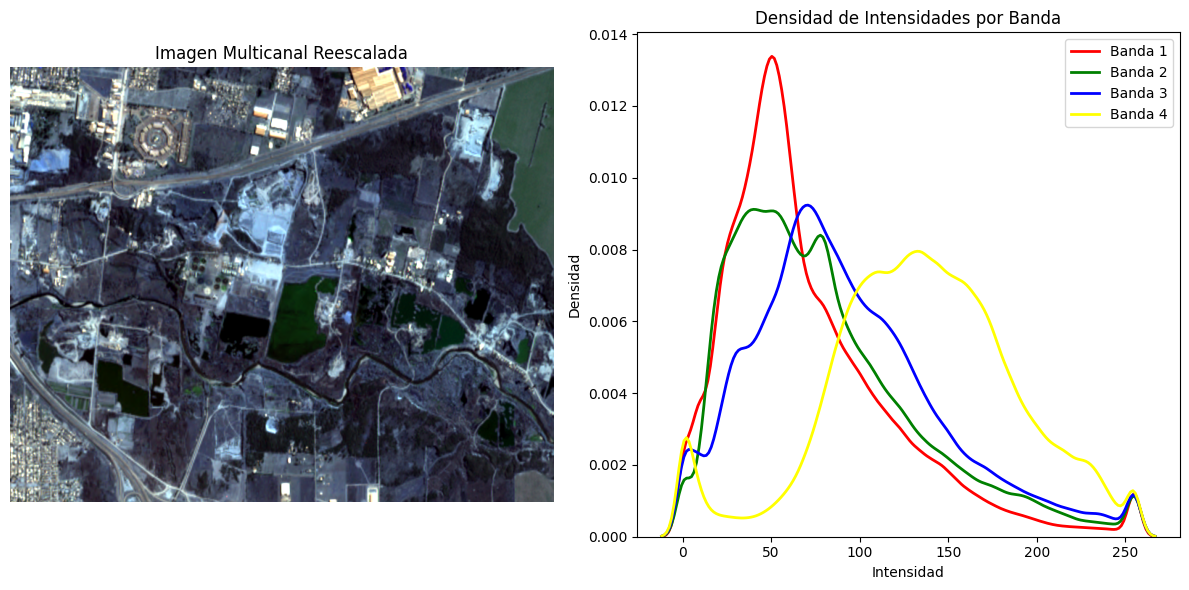

In [38]:
# Crear la figura con 1 fila y 2 columnas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Mostrar la imagen (suponiendo que tiene múltiples bandas)
ax[0].imshow(imagen_escalada[:,:,:3]) # Estamos mostrando solo las primeras 3 bandas
ax[0].set_title("Imagen Multicanal Reescalada")
ax[0].axis("off")

# Colores para cada banda en el histograma
colores = ["red", "green", "blue", "yellow"]

# Dibujar curvas de densidad para cada banda
for i in range(imagen_escalada.shape[-1]):  # Hasta 4 bandas
    sns.kdeplot(imagen_escalada[:,:,i].ravel(), color=colores[i], label=f"Banda {i+1}", ax=ax[1], linewidth=2)

ax[1].set_title("Densidad de Intensidades por Banda")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Densidad")
ax[1].legend()

plt.tight_layout()
plt.show()

## 2.3. Sistematizar los pasos en una función

Así como diseñamos una función para hacer el escalado de una sola imagen, podemos pensar en otra que lo haga para estas imágenes multibanda o multicanal. Antes de pensar en la función en sí, ¿Cómo podríamos indicar que se haga el escalado _para cada banda_? Esto lo solucionamos usando un ciclo de tipo _for_ sobre alguna variable que sea _iterable_.

Pero, ¿qué significa que una variable sea iterable? Quiere decir que podemos _recorrer_ sus elementos uno a uno, y capturar algún valor o atributo de esos elementos en cada iteración o _pasada_. Por ejemplo, si nosotros necesitamos recorrer 4 canales o bandas, podríamos leer ese número haciendo `imagen_spot_apilada.shape[-1]`, lo cual nos devuelve `4` (`[-1]`indica el último elemento de .shape). Si nosotros sobre ese `4`(o sobre cualquier número) aplicamos la función `range`, obtenemos una secuencia de números del 0 al 3 (excluyendo el 4). Esta secuencie es iterable:

```python
canales = imagen_spot_apilada.shape[-1]


for i in range(canales):
    # Itera sobre i, asignando los valores de 0 a 3 e
    # imprimiendo su valor seguido un salto de línea
    print(i, '\n')
```

In [39]:
canales = imagen_spot_apilada.shape[-1]


for i in range(canales):
    # Itera sobre i, asignando los valores de 0 a 3 e
    # imprimiendo su valor seguido un salto de línea
    print(i, '\n')

0 

1 

2 

3 



Entonces, en el código anterior podríamos usar ese `i` para recorrer nuestra imagen `imagen_spot_apilada` a lo largo de su tercera dimensión:

```python
for i in range(canales):
  canal = imagen_spot_apilada[:, :, i]
  print(f'Banda o canal {i}, dimensiones: {canal.shape}')
```

In [40]:
for i in range(canales):
  canal = imagen_spot_apilada[:, :, i]
  print(f'Banda o canal {i}, dimensiones: {canal.shape}')

Banda o canal 0, dimensiones: (600, 750)
Banda o canal 1, dimensiones: (600, 750)
Banda o canal 2, dimensiones: (600, 750)
Banda o canal 3, dimensiones: (600, 750)


Con ese concepto incorporado, podemos crear un array vacío con la misma estructura que `imagen_spot_apilada` e ir usando el _for_ para escalar cada uno de los canales o bandas y guardarnos en este nuevo array:

```python
# Crear un array vacio con la misma estructura que imagen_spot_apilada
imagen_escalada = np.empty_like(imagen_spot_apilada)

# Definir una variable con el número de canales
canales = imagen_escalada.shape[-1]

# Escalar una a una las bandas (usando p=1)
for i in range(canales):
  canal = imagen_spot_apilada[:, :, i]
  imagen_escalada[:, :, i] = escalar_imagen(canal, 1)

# Convertir a np.uint8 el array escalado (no hace falta seguir usando float)
imagen_escalada = np.uint8(imagen_escalada)
```

In [41]:
# Crear un array vacio con la misma estructura que imagen_spot_apilada
imagen_escalada = np.empty_like(imagen_spot_apilada)

# Definir una variable con el número de canales
canales = imagen_escalada.shape[-1]

# Escalar una a una las bandas (usando p=1)
for i in range(canales):
  canal = imagen_spot_apilada[:, :, i]
  imagen_escalada[:, :, i] = escalar_imagen(canal, 1)

# Convertir a np.uint8 el array escalado (no hace falta seguir usando float)
imagen_escalada = np.uint8(imagen_escalada)

Ahora que ya tenemos el código o bloque principal, podemos crear una nueva función, con algunos pequeños cambios para hacerla más general. Por ejemplo, el valor de percentil pasa a ser un parámetro `p`y la imagen puede ser cualquier array con la estructura `(filas, columnas, bandas)`:


```python
def escalar_imagen_multibanda(imagen, p):
  # Crear un array vacio con la misma estructura que imagen_spot_apilada
  imagen_escalada = np.empty_like(imagen)

  # Definir una variable con el número de canales
  canales = imagen_escalada.shape[-1]

  # Escalar una a una las bandas (usando p)
  for i in range(canales):
    canal = imagen[:, :, i]
    imagen_escalada[:, :, i] = escalar_imagen(canal, p)

  # Convertir a np.uint8 el array escalado (no hace falta seguir usando float)
  imagen_escalada = np.uint8(imagen_escalada)

  return imagen_escalada

# Probar la función:
imagen_escalada_funcion = escalar_imagen_multibanda(imagen_spot_apilada, 1)

fig, ax = plt.subplots()
ax.imshow(imagen_escalada_funcion[:, :, :3])
ax.axis("off")
plt.show()
```

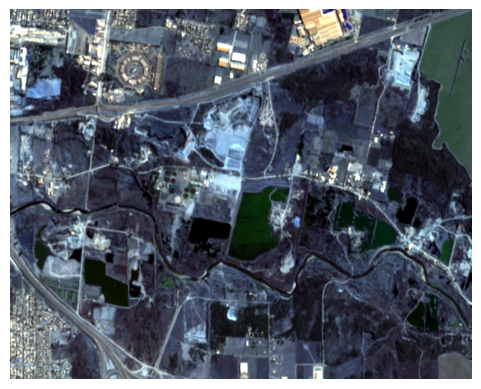

In [42]:
def escalar_imagen_multibanda(imagen, p):
  # Crear un array vacio con la misma estructura que imagen_spot_apilada
  imagen_escalada = np.empty_like(imagen)

  # Definir una variable con el número de canales
  canales = imagen_escalada.shape[-1]

  # Escalar una a una las bandas (usando p)
  for i in range(canales):
    canal = imagen[:, :, i]
    imagen_escalada[:, :, i] = escalar_imagen(canal, p)

  # Convertir a np.uint8 el array escalado (no hace falta seguir usando float)
  imagen_escalada = np.uint8(imagen_escalada)

  return imagen_escalada

# Probar la función:
imagen_escalada_funcion = escalar_imagen_multibanda(imagen_spot_apilada, 1)

fig, ax = plt.subplots()
ax.imshow(imagen_escalada_funcion[:, :, :3])
ax.axis("off")
plt.show()

## 2.4. Cambiar el orden de los canales RGB

Por defecto, _imshow()_ muestra los primeros tres canales de `imagen_escalada`. Esto lo podemos modificar usando el _slicing_ de `NumPy`, en este caso sobre la última dimensión. Por ejemplo, si quisiéramos ver la tercer banda en el canal _rojo_, la segunda en el _verde_ y la primera en el _azul_, podríamos hacer:

```python
plt.figure()
plt.imshow(imagen_escalada_funcion[:,:,[2,1,0]])
plt.axis("off")
plt.title("Rojo - Verde - Azul")
plt.show()
```

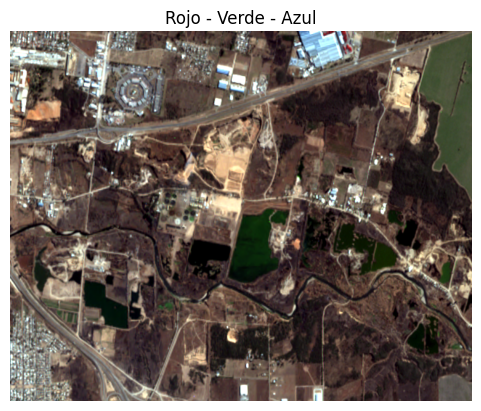

In [43]:
plt.figure()
plt.imshow(imagen_escalada_funcion[:,:,[2,1,0]])
plt.axis("off")
plt.title("Rojo - Verde - Azul")
plt.show()

Y así, podemos probar con otras combinaciones u órdenes de los canales:

```python
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(imagen_escalada_funcion[:,:,[3,2,1]])
ax[0].axis("off")
ax[0].set_title("Infrarrojo - Rojo - Verde")

ax[1].imshow(imagen_escalada_funcion[:,:,[2,1,0]])
ax[1].axis("off")
ax[1].set_title("Rojo - Verde - Azul")

ax[2].imshow(imagen_escalada_funcion[:,:,[2,3,1]])
ax[2].axis("off")
ax[2].set_title("Rojo - Infrarrojo - Verde")

plt.show()
```

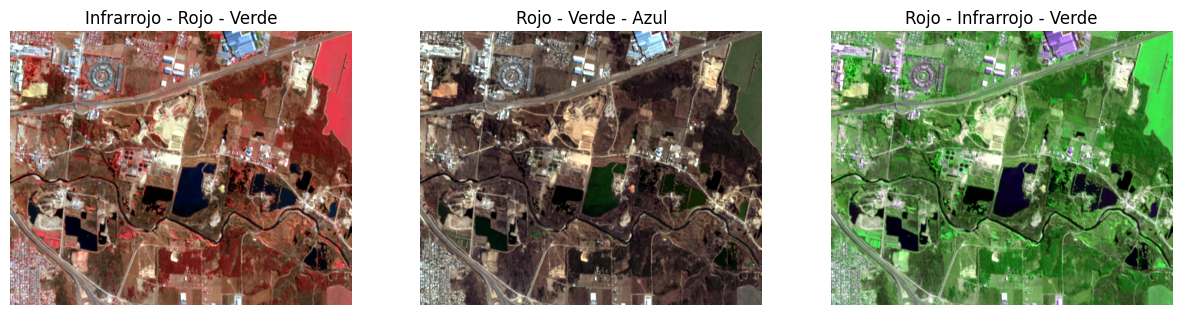

In [44]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(imagen_escalada_funcion[:,:,[3,2,1]])
ax[0].axis("off")
ax[0].set_title("Infrarrojo - Rojo - Verde")

ax[1].imshow(imagen_escalada_funcion[:,:,[2,1,0]])
ax[1].axis("off")
ax[1].set_title("Rojo - Verde - Azul")

ax[2].imshow(imagen_escalada_funcion[:,:,[2,3,1]])
ax[2].axis("off")
ax[2].set_title("Rojo - Infrarrojo - Verde")

plt.show()

## Ejercicio

En la Clase 02 ahondaremos en la interpretación de los colores en estas imágenes, dado que se explican por la manera en que el sensor mide distintas superficies u objetos que hay en la superficie.

Ahora dejamos el siguiente ejercicio. Abrir esta imagen multicanal correspondiente a un instrumento de otro satélite (Sentinel-2), usando `scikit-image`:

```python
import gdown
from skimage import io

# ID del archivo de Google Drive
file_id = "1xf-K12ZeqdI7rxF4B8Z5_nHaGpv11028"
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar la imagen
output = "sentinel_apilada.tif"
gdown.download(url, output, quiet=False)

# Cargar y mostrar la imagen
imagen_sentinel_multicanal = io.imread(output)
```

Responder:

- ¿Qué dimensiones tiene la imagen? ¿Cuántos canales o bandas contiene?
- ¿De qué tipo de dato se trata?

Luego, aplicá la función `escalar_imagen_multibanda` sobre este nuevo array, y probá las visualizaciones con distintas combinaciones de canales. Tené en cuenta que _imshow()_ no sabe cómo interpretar imágenes de más de 4 canales, por lo que deberás siempre pasarle la imagen con un _slicing_ aplicado sobre la misma. Por ejemplo, suponiendo que tu resultado se llama `imagen_sentinel_escalada`:

```python
fig, ax = plt.subplots()
ax.imshow(imagen_sentinel_escalada[:, :, :3])
plt.show()
```

O alternativamente:

```python
fig, ax = plt.subplots()
plt.imshow(imagen_sentinel_escalada[:,:,[2,1,0]])
plt.show()
```